<a href="https://colab.research.google.com/github/crovillo/DS3000-AI-vs-Human-Detection-/blob/main/DS3000_AIvsHumanDetection_Group13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DS3000: AI vs HumanDetection** #
## **Group 13** ##

| Member | Contributions |
|---|---|
| Caleb Rovillos | Coded the EDA to create the graphs tso visualize the data. Also organized the data in the Data and Cleaning section (Section 3) to identify cleaning needs and to identify any unusual outliers or ranges.|
| Lana Abdallah | Coded the Dataset Loading section(1). Also did the split diagrams/tables(5). Also roughly codded the Logistic Regression and KNN, without comparison(7-ish). |
| Name 3 | |
| Name 4 | |

## **1. Dataset Loading**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

<font size="1" color="#444444">قد يقال</font>

**Explanation:** This cell imports the libraries used for data processing and visualization. Setting a random seed helps keep random operations reproducible.

In [ ]:
import kagglehub, glob, os

path = kagglehub.dataset_download("pratyushpuri/ai-vs-human-content-detection-1000-record-in-2025")
csv_file = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
print(csv_file)

100%|██████████| 519k/519k [00:00<00:00, 1.23MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/pratyushpuri/ai-vs-human-content-detection-1000-record-in-2025/versions/1/ai_human_content_detection_dataset.csv


<font size="1" color="#444444">قد يقال</font>

**Explanation:** This cell downloads the approved AI-versus-human content dataset from Kaggle and finds its CSV file so the notebook can load it.

In [ ]:
df = pd.read_csv(csv_file)
print(df.shape)
df.head()

(1367, 17)


,text_content,content_type,word_count,character_count,sentence_count,lexical_diversity,avg_sentence_length,avg_word_length,punctuation_ratio,flesch_reading_ease,gunning_fog_index,grammar_errors,passive_voice_ratio,predictability_score,burstiness,sentiment_score,label
0,Score each cause. Quality throughout beautiful...,academic_paper,288,1927,54,0.9514,5.33,5.69,0.0280,53.08,7.41,1,0.1041,105.86,0.5531,0.2034,1
1,Board its rock. Job worker break tonight coupl...,essay,253,1719,45,0.9723,5.62,5.80,0.0262,50.32,8.10,6,0.2045,100.29,0.5643,0.4854,1
2,Way debate decision produce. Dream necessary c...,academic_paper,420,2849,75,0.9071,5.60,5.79,0.0263,46.86,7.86,5,0.2308,96.88,0.4979,-0.2369,1
3,Story turn because such during open model. Tha...,creative_writing,196,1310,34,0.9592,5.76,5.69,0.0260,53.80,7.00,2,0.1912,88.79,0.6241,NaN,1
4,Place specific as simply leader fall analysis....,news_article,160,1115,28,0.9688,5.71,5.97,0.0251,44.53,8.29,0,0.1318,26.15,0.2894,NaN,1


<font size="1" color="#444444">قد يقال</font>

**Explanation:** This cell loads the dataset into a pandas DataFrame, checks its dimensions (1,367 rows and 17 columns), and previews the first records.

## **2. Problem Statement**

Can we tell whether a piece of text is AI generated or made by a human.

## **3. Data and Cleaning**

In [ ]:
audit = pd.DataFrame({
    "type": df.dtypes,
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique values": df.nunique(),
})
audit

,type,missing,% missing,unique values
text_content,object,0,0.00,1367
content_type,object,0,0.00,8
word_count,int64,0,0.00,359
character_count,int64,0,0.00,974
sentence_count,int64,0,0.00,82
lexical_diversity,float64,0,0.00,522
avg_sentence_length,float64,0,0.00,166
avg_word_length,float64,0,0.00,152
punctuation_ratio,float64,0,0.00,145
flesch_reading_ease,float64,79,5.78,984


<font size="1" color="#444444">قد يقال</font>

**Explanation:** This data-quality audit lists each column’s data type, missing-value count and percentage, and number of unique values. These checks help identify cleaning needs before modelling.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate texts:", df["text_content"].duplicated().sum())
print("\nTarget Balance:\n", df["label"].value_counts())
print("\nContent Types:\n", df["content_type"].value_counts())

Duplicate rows: 0
Duplicate texts: 0

Target Balance:
 label
0    684
1    683
Name: count, dtype: int64

Content Types:
 content_type
academic_paper      189
news_article        185
blog_post           183
creative_writing    172
article             171
essay               161
social_media        154
product_review      152
Name: count, dtype: int64


<font size="1" color="#444444">قد يقال</font>

**Explanation:** This cell checks for duplicate records and repeated text, then displays the number of examples in each target class and content category. The labels are almost perfectly balanced (684 human and 683 AI), with no duplicate rows or duplicate texts reported.

In [ ]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
word_count,1367.0,140.191,97.410,3.000,61.500,131.000,193.000,443.000
character_count,1367.0,940.329,654.335,14.000,410.500,882.000,1294.500,2966.000
sentence_count,1367.0,25.610,17.867,1.000,11.000,24.000,35.000,83.000
lexical_diversity,1367.0,0.968,0.026,0.875,0.952,0.969,0.989,1.000
avg_sentence_length,1367.0,5.486,0.447,3.000,5.270,5.480,5.700,8.000
avg_word_length,1367.0,5.718,0.280,4.000,5.590,5.710,5.830,8.330
punctuation_ratio,1367.0,0.027,0.003,0.019,0.026,0.027,0.028,0.071
flesch_reading_ease,1288.0,52.183,10.467,-50.010,47.712,52.190,57.323,98.870
gunning_fog_index,1332.0,7.557,1.867,1.200,6.620,7.515,8.390,27.870
grammar_errors,1367.0,1.538,1.912,0.000,0.000,1.000,3.000,10.000


<font size="1" color="#444444">قد يقال</font>

**Explanation:** The descriptive statistics summarize numerical features such as their averages, spread, and minimum and maximum values. We use them to identify unusual ranges or potential outliers before training.

The value ranges look valid, there are no negative countsm ratios are within 0 and 1, and sentiment is within -1 and 1. A few extreme readability scores (Flesch min of -50, Gunning Fog max 27.9) are possible for very complex texts, so we can keep these instead of remove them. "label" has a mean of 0.5, so the classes are balanced.

## **4. Exploratory Data Analysis (EDA)**

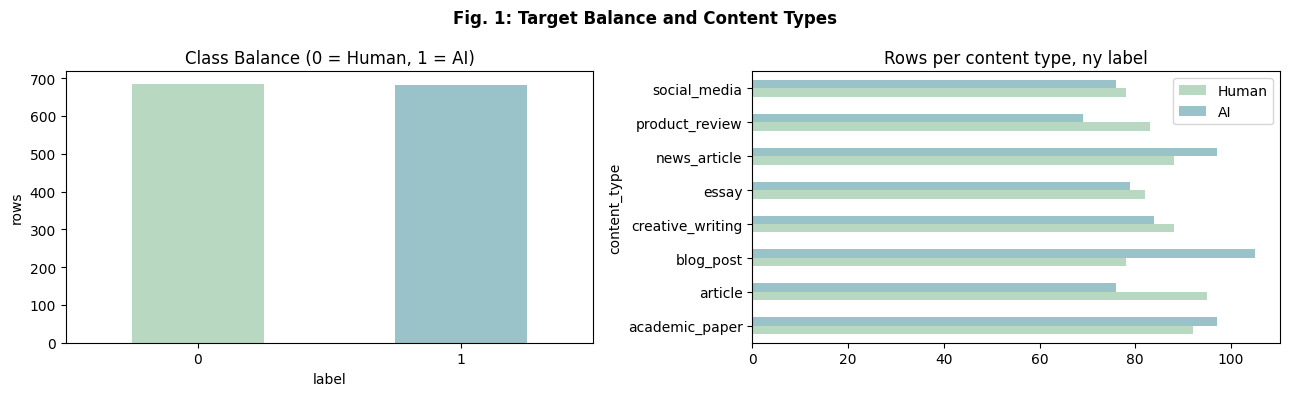

In [ ]:
fig, axes = plt.subplots(1, 2, figsize = (13, 4))

df["label"].value_counts().plot.bar(ax = axes[0], color = ["#B9D8C2", "#9AC2C9"], rot = 0)
axes[0].set_title("Class Balance (0 = Human, 1 = AI)")
axes[0].set_ylabel("rows")

pd.crosstab(df["content_type"], df["label"]).plot.barh(ax = axes[1], color = ["#B9D8C2", "#9AC2C9"])
axes[1].set_title("Rows per content type, ny label")
axes[1].legend(["Human", "AI"])

plt.suptitle("Fig. 1: Target Balance and Content Types", fontweight = "bold")
plt.tight_layout()
plt.show()

<font size="1" color="#444444">قد يقال</font>

**Explanation:** Figure 1 shows the overall human-versus-AI class balance and how those two classes are distributed across content types. This helps us judge whether the dataset is balanced and whether content categories might affect the analysis.

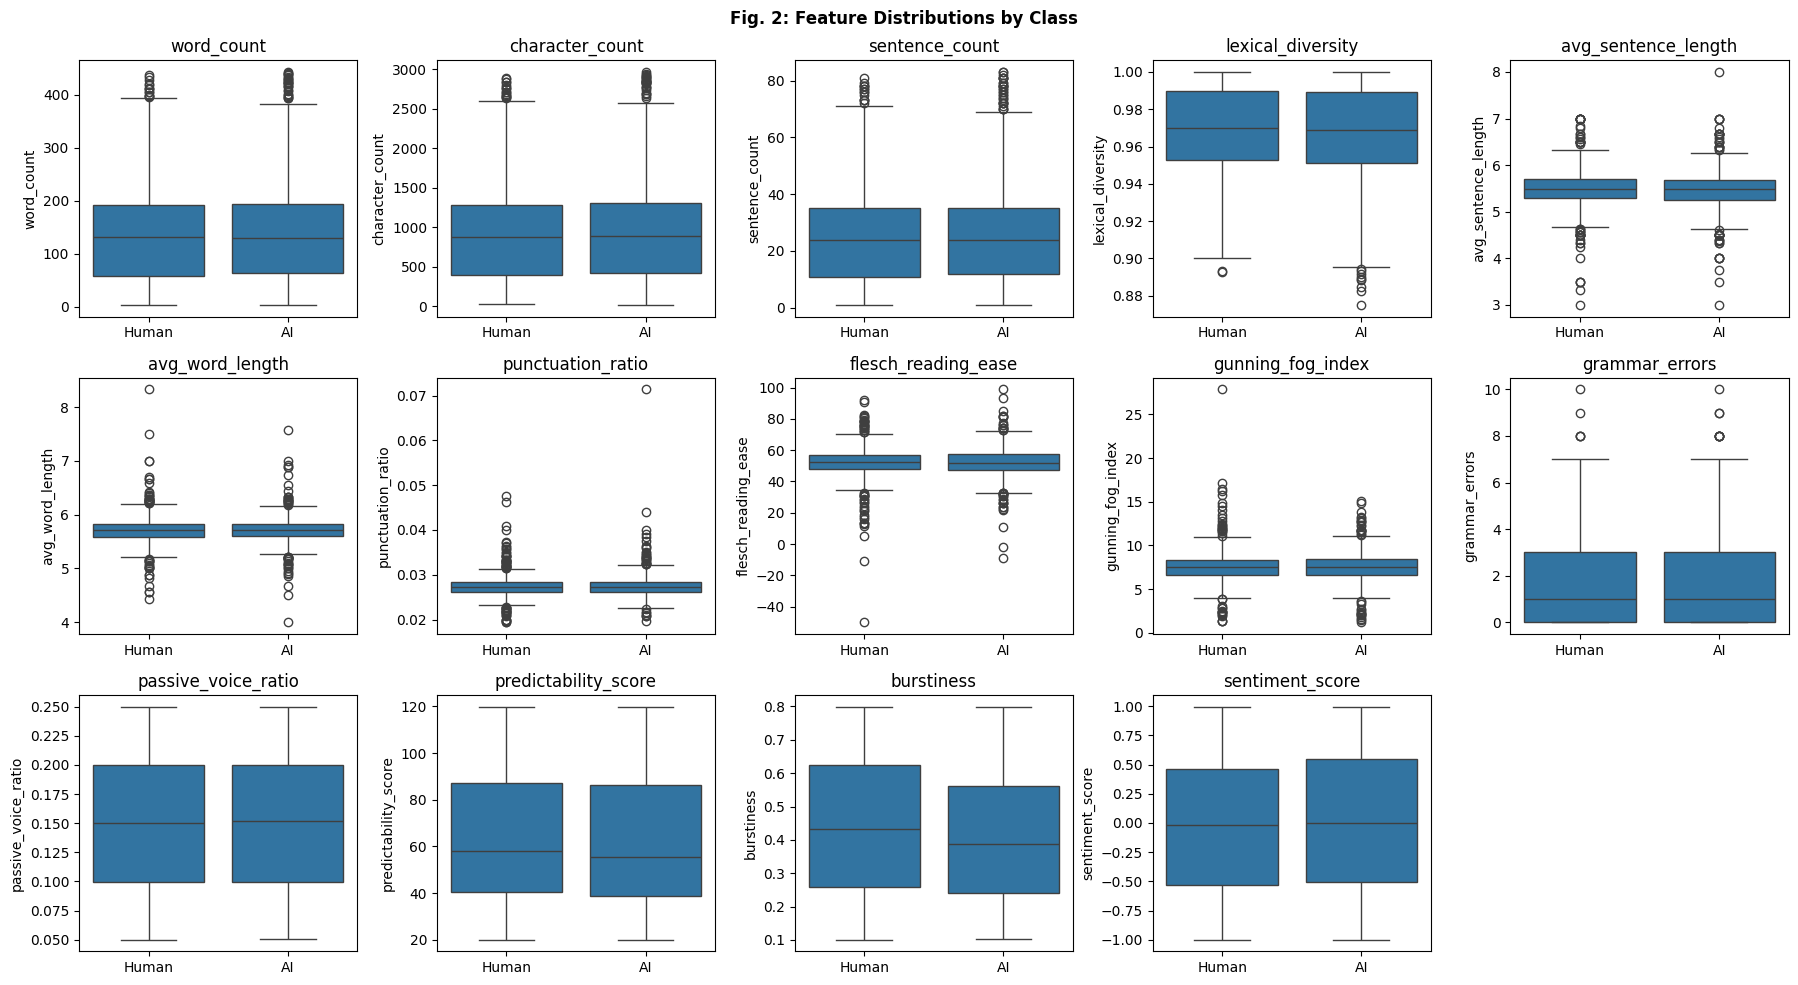

In [ ]:
#do the features look different for AI vs Human?
num_cols = df.select_dtypes("number").columns.drop("label")

fig, axes = plt.subplots(3, 5, figsize = (18, 10))
for ax, col in zip(axes.flat, num_cols):
  sns.boxplot(data = df, x = "label", y = col, ax = ax)
  ax.set_title(col)
  ax.set_xlabel("")
  ax.set_xticks([0, 1], ["Human", "AI"])
axes.flat[-1].axis("off")

plt.suptitle("Fig. 2: Feature Distributions by Class", fontweight = "bold")
plt.tight_layout()
plt.show()

<font size="1" color="#444444">قد يقال</font>

**Explanation:** Figure 2 uses boxplots to compare each numerical feature for human-written and AI-generated texts. Differences or overlaps between the boxes provide an initial indication of how useful the available features may be for classification.



---



## **5. Split diagram/table; scaler and imputer**

### **Train / Validation / Test**



In [ ]:
# PICKING FEATURES

X = df.drop(columns=["text_content", "label"])
X = pd.get_dummies(X, columns=["content_type"], dtype=int)
y = df["label"]

print(X.shape)

(1367, 22)


<font size="1" color="#444444">قد يقال</font>

**Explanation:** This cell separates the target label (`y`) from the input features (`X`). It excludes raw text from the inputs and converts the categorical `content_type` column into numerical indicator columns, giving 22 model input features.

In [ ]:
# SPLIT 60/20/20

from sklearn.model_selection import train_test_split

# 1. take 20% out for the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# split remaining 80% into train (60%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

<font size="1" color="#444444">قد يقال</font>

**Explanation:** This cell divides the dataset into training (60%), validation (20%), and test (20%) sets. Stratification keeps the human/AI proportions similar in each split, while the fixed seed makes the split reproducible. The test set should be reserved for final evaluation.

In [ ]:
# ACTUALLY DOING THE SPLIT DIAGRAM/TABLE PART

split_table = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "% of data": [len(y_train)/len(y)*100, len(y_val)/len(y)*100, len(y_test)/len(y)*100],
    "% AI": [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100],
}, index=["train", "validation", "test"]).round(1)
split_table


,rows,% of data,% AI
train,819,59.9,49.9
validation,274,20.0,50.0
test,274,20.0,50.0


<font size="1" color="#444444">قد يقال</font>

**Explanation:** The split table verifies how many samples are in each partition and the percentage labelled AI. This documents the data division and helps confirm that the class balance was preserved.

### Imputer and Scaler ###

In [ ]:
# FIT ON TRAINING DATA ONLY

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# fill missing values with the TRAINING median
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_val_imp   = imputer.transform(X_val)
X_test_imp  = imputer.transform(X_test)

# put all features on the same scale, using TRAINING data only
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_val_s   = scaler.transform(X_val_imp)
X_test_s  = scaler.transform(X_test_imp)

print("Missing values left:", np.isnan(X_train_s).sum(), np.isnan(X_val_s).sum(), np.isnan(X_test_s).sum())

Missing values left: 0 0 0


<font size="1" color="#444444">قد يقال</font>

**Explanation:** The imputer fills missing feature values using medians learned only from the training data. StandardScaler then standardizes features using training-set statistics. The same fitted transformations are applied to validation and test data to reduce data leakage; the output reports zero missing values after processing.

## **7. Baseline Models**

###Comparing Logistic Regression and KNN. ###

### All models are trained with the same inputs, loss, metrics and validation protocol as traditional baselines. ###

In [ ]:
# IMPORTS: models +metrics needed from scikit-learn.
# also added time to measure how long they take

import time
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

<font size="1" color="#444444">قد يقال</font>

**Explanation:** These imports provide the two classifiers, classification metrics (accuracy, precision, recall, and F1), and timing functionality needed to compare model performance.

In [ ]:
# Scoring Function
results = []

def score(name, y_pred, train_time, predict_time):
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred, zero_division=0),
        "recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "train time (s)": train_time,
        "predict time (s)": predict_time,
    })

<font size="1" color="#444444">قد يقال</font>

**Explanation:** This reusable scoring function records each model’s validation-set accuracy, precision, recall, F1 score, training time, and prediction time in a common results list. Using the same metrics supports a fair comparison.

### Logistic Regression: ###

In [ ]:
# Logistic Regression finds a straight dividing line between the two classes.
# For each text it gives a probability of being AI (between 0 and 1)
# and predicts AI if that's above 0.5.

logreg = LogisticRegression(max_iter=1000, random_state=SEED)

start = time.time()
logreg.fit(X_train_s, y_train)
t_train = time.time() - start

start = time.time()
pred = logreg.predict(X_val_s)
t_pred = time.time() - start

score("Logistic Regression", pred, t_train, t_pred)

<font size="1" color="#444444">قد يقال</font>

**Explanation:** Logistic Regression is trained on scaled training features, then used to classify validation samples as AI or human. This cell measures fitting and prediction time and passes its validation results to the shared scoring function.

### KNN: ###

In [ ]:
# For each new text, KNN finds 5 most similar texts in training set and goes with majority vote.
# relies on distances, which is why scaling the features was important.

knn = KNeighborsClassifier(n_neighbors=5)

start = time.time()
knn.fit(X_train_s, y_train)
t_train = time.time() - start

start = time.time()
pred = knn.predict(X_val_s)
t_pred = time.time() - start

score("KNN (k=5)", pred, t_train, t_pred)

<font size="1" color="#444444">قد يقال</font>

**Explanation:** KNN (k=5) predicts each validation sample’s label from the five nearest training samples. Scaling matters because KNN depends on feature distances. Its validation predictions and runtime are recorded using the same scoring function.

### Comparison Table:

In [ ]:
from sklearn.dummy import DummyClassifier

# Simple reference baseline: always predicts the most common class
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_s, y_train)

dummy_pred = dummy.predict(X_val_s)
baseline_acc = accuracy_score(y_val, dummy_pred)

parameters = {
    "Logistic Regression": "max_iter=1000",
    "KNN (k=5)": "k=5"
}

comparison = pd.DataFrame(results)
comparison["parameters"] = comparison["model"].map(parameters)
comparison["baseline improvement (pp)"] = (
    comparison["accuracy"] - baseline_acc
) * 100
comparison = comparison.rename(
    columns={"predict time (s)": "validation time (s)"}
)

comparison = comparison[[
    "model",
    "parameters",
    "accuracy",
    "precision",
    "recall",
    "F1",
    "train time (s)",
    "validation time (s)",
    "baseline improvement (pp)"
]]

print("Majority-class baseline accuracy:", round(baseline_acc, 4))
display(comparison.round(4))

# Select the model with the best validation F1 score
best_name = comparison.loc[comparison["F1"].idxmax(), "model"]

models = {
    "Logistic Regression": logreg,
    "KNN (k=5)": knn
}

best_model = models[best_name]

# Evaluate the selected model on the untouched test set
start = time.perf_counter()
test_pred = best_model.predict(X_test_s)
test_time = time.perf_counter() - start

print("Best model:", best_name)
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Test precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("Test F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("Test prediction time (s):", round(test_time, 6))

Majority-class baseline accuracy: 0.5


,model,parameters,accuracy,precision,recall,F1,train time (s),validation time (s),baseline improvement (pp)
0,Logistic Regression,max_iter=1000,0.4964,0.4965,0.5109,0.5036,0.0911,0.0029,-0.3650
1,KNN (k=5),k=5,0.5182,0.5197,0.4818,0.5000,0.0034,0.1048,1.8248


Best model: Logistic Regression
Test accuracy: 0.4818
Test precision: 0.4806
Test recall: 0.4526
Test F1: 0.4662
Test prediction time (s): 0.000646


<font size="1" color="#444444">قد يقال</font>

We compared Logistic Regression and KNN using accuracy, precision, recall, F1 score, and training and prediction times. KNN had slightly higher validation accuracy (51.82% vs. 49.64%), while Logistic Regression had a slightly higher F1 score (0.5036 vs. 0.5000). The code selected Logistic Regression for final testing because it had the highest validation F1 score. Logistic Regression achieved 48.18% accuracy on the test set. Both models performed close to the 50% baseline.

<font size="1" color="#444444">قد يقال</font>

## 8. Concrete Conclusion and Unresolved Risk

**Concrete Conclusion:**

The baseline models showed limited ability to distinguish AI-generated text from human-written text. KNN achieved 51.82% validation accuracy, compared with 49.64% for Logistic Regression. Although KNN had slightly higher accuracy, Logistic Regression had a slightly higher F1 score (0.5036 versus 0.5000). Both models performed close to the 50% majority-class baseline, so the current models and features do not yet provide reliable classification.

**Unresolved Risk:**

The current numerical and linguistic features may not capture enough meaningful differences between AI-generated and human-written text. Because validation performance is near the baseline, the models may have difficulty generalizing to unseen examples. In Stage 2, we will investigate whether models such as Random Forest and MLP improve validation performance while monitoring for overfitting.
